In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, balanced_accuracy_score
from sklearn.metrics import confusion_matrix

In [3]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as  sns

In [4]:
iris = load_iris()

X = iris.data
y = iris.target

In [5]:
print("Nama Fitur:", iris.feature_names)
print("Nama Target(Spesies):", iris.target_names)
print("Bentuk data X:", X.shape)
print("Bentuk data y:", y.shape)
print("\nBeberapa baris pertama data (X):\n", X[:5])
print("\nBeberapa baris pertama label (y):\n", y[:5])

Nama Fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Nama Target(Spesies): ['setosa' 'versicolor' 'virginica']
Bentuk data X: (150, 4)
Bentuk data y: (150,)

Beberapa baris pertama data (X):
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]

Beberapa baris pertama label (y):
 [0 0 0 0 0]


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
print("\nBentuk X_train:", X_train.shape)
print("Bentuk X_test:", X_test.shape)
print("Bentuk y_train:", y_train.shape)
print("Bentuk y_test:", y_test.shape)


Bentuk X_train: (112, 4)
Bentuk X_test: (38, 4)
Bentuk y_train: (112,)
Bentuk y_test: (38,)


In [7]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
print("\nModel KNN telah dilatih")


Model KNN telah dilatih


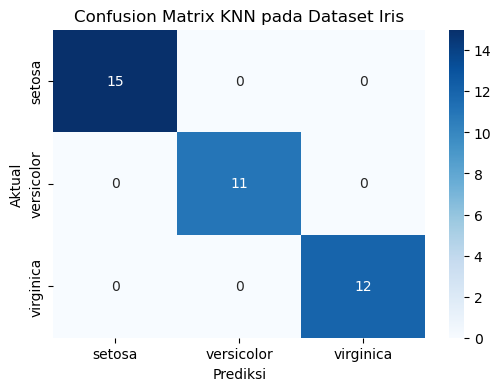

In [9]:
y_pred = knn.predict(X_test)  # ganti knn dengan nama model KNN-mu

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix KNN pada Dataset Iris")
plt.show()

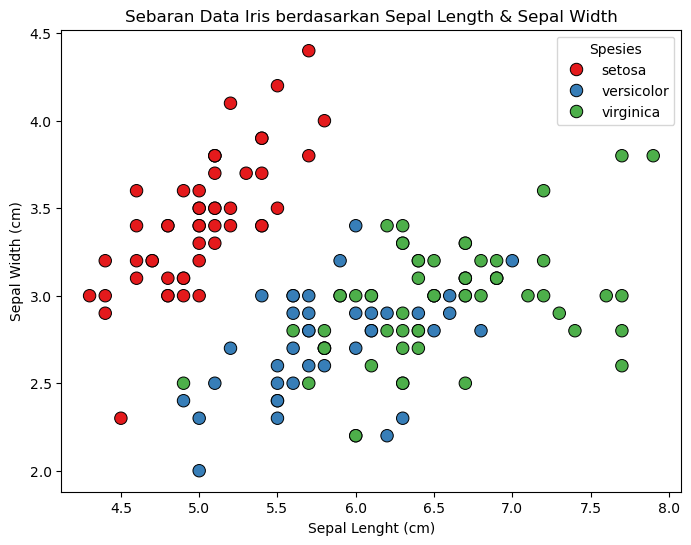

In [14]:
plt.figure(figsize=(8,6))
sns.scatterplot(x=X[:,0], y=X[:,1], hue=iris.target_names[y], palette="Set1", s=80, edgecolor="k")

plt.xlabel("Sepal Lenght (cm)")
plt.ylabel("Sepal Width (cm)")
plt.title("Sebaran Data Iris berdasarkan Sepal Length & Sepal Width")
plt.legend(title="Spesies")
plt.show()

In [15]:
import pandas as pd
iris = pd.read_csv('flags_test_fold_1.csv')

In [16]:
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 26 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   landmass    19 non-null     int64  
 1   zone        19 non-null     int64  
 2   area        19 non-null     float64
 3   population  19 non-null     float64
 4   language    19 non-null     int64  
 5   religion    19 non-null     int64  
 6   bars        19 non-null     float64
 7   stripes     19 non-null     float64
 8   colours     19 non-null     float64
 9   circles     19 non-null     float64
 10  crosses     19 non-null     float64
 11  saltires    19 non-null     float64
 12  quarters    19 non-null     float64
 13  sunstars    19 non-null     float64
 14  crescent    19 non-null     int64  
 15  triangle    19 non-null     int64  
 16  icon        19 non-null     int64  
 17  animate     19 non-null     int64  
 18  text        19 non-null     int64  
 19  red         19 non-null     int

In [17]:
iris.head()

,landmass,zone,area,population,language,religion,bars,stripes,colours,circles,...,icon,animate,text,red,green,blue,yellow,white,black,orange
0,3,1,0.0,0.0,6,0,3.0,0.0,3.0,0.0,...,0,0,0,1,0,1,1,0,0,0
1,6,2,7690.0,15.0,1,1,0.0,0.0,3.0,0.0,...,0,0,0,1,0,1,0,1,0,0
2,5,1,143.0,90.0,6,2,0.0,0.0,2.0,1.0,...,0,0,0,1,1,0,0,0,0,0
3,2,3,1099.0,6.0,2,0,0.0,3.0,3.0,0.0,...,0,0,0,1,1,0,1,0,0,0
4,4,2,28.0,4.0,10,5,0.0,0.0,3.0,1.0,...,0,0,0,1,1,0,0,1,0,0


In [19]:
iris.drop('landmass',axis=1,inplace=True)

In [22]:
iris.columns = iris.columns.str.strip()
print(iris.columns.tolist())

['zone', 'area', 'population', 'language', 'religion', 'bars', 'stripes', 'colours', 'circles', 'crosses', 'saltires', 'quarters', 'sunstars', 'crescent', 'triangle', 'icon', 'animate', 'text', 'red', 'green', 'blue', 'yellow', 'white', 'black', 'orange']


In [24]:
from sklearn.model_selection import train_test_split

label_cols = ['red', 'green', 'blue', 'yellow', 'white', 'black', 'orange']

X = iris.drop(columns=label_cols)
y = iris[label_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=123
)

In [29]:
from sklearn.tree import DecisionTreeClassifier
tree_model = DecisionTreeClassifier()
tree_model = tree_model.fit(X_train, y_train)

In [31]:
from sklearn.metrics import accuracy_score
y_pred = tree_model.predict(X_test)

acc_secore = round(accuracy_score(y_pred, y_test),3)
print('Accuracy:',acc_secore)

Accuracy: 0.0


In [35]:
pred = tree_model.predict(X_test.iloc[[0]])[0]

print("Hasil prediksi:", pred)
print("Warna yang diprediksi:", [
    warna for warna, nilai in zip(label_cols, pred) if nilai == 1
])

Hasil prediksi: [1 1 0 0 0 1 0]
Warna yang diprediksi: ['red', 'green', 'black']


In [12]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_graphviz

# Muat data latih flags (bukan dataset Iris)
flags = pd.read_csv("flags_train_fold_1.csv")

label_cols = ['red', 'green', 'blue', 'yellow', 'white', 'black', 'orange']
X = flags.drop(columns=label_cols)
y = flags[label_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=123
)

tree_model = DecisionTreeClassifier(random_state=123)
tree_model.fit(X_train, y_train)

export_graphviz(
    tree_model,
    out_file="flags_tree.dot",
    feature_names=X_train.columns.tolist(),
    rounded=True,
    filled=True
)

print("Berhasil: flags_tree.dot sudah dibuat")

Berhasil: flags_tree.dot sudah dibuat


In [13]:
import numpy as np
flags = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9,])
warna = np.array([2, 4, 2, 2, 2, 2, 3, 2])

In [19]:
import pandas as pd

flags_df = pd.read_csv("flags_train_fold_1.csv")
print(flags_df.columns.tolist())
display(flags_df.head())

['landmass', 'zone', 'area', 'population', 'language', 'religion', 'bars', 'stripes', 'colours', 'circles', 'crosses', 'saltires', 'quarters', 'sunstars', 'crescent', 'triangle', 'icon', 'animate', 'text', 'red', 'green', 'blue', 'yellow', 'white', 'black', 'orange']


,landmass,zone,area,population,language,religion,bars,stripes,colours,circles,...,icon,animate,text,red,green,blue,yellow,white,black,orange
0,5,1,648.0,16.0,10,2,0.0,3.0,5.0,0.0,...,1,0,0,1,1,0,1,1,1,0
1,3,1,29.0,3.0,6,6,0.0,0.0,3.0,0.0,...,0,1,0,1,0,0,1,0,1,0
2,4,1,2388.0,20.0,8,2,2.0,0.0,3.0,0.0,...,0,0,0,1,1,0,0,1,0,0
3,6,3,0.0,0.0,1,1,0.0,0.0,5.0,0.0,...,1,1,0,1,0,1,1,1,0,1
4,4,2,1247.0,7.0,10,5,0.0,2.0,3.0,0.0,...,1,0,0,1,0,0,1,0,1,0


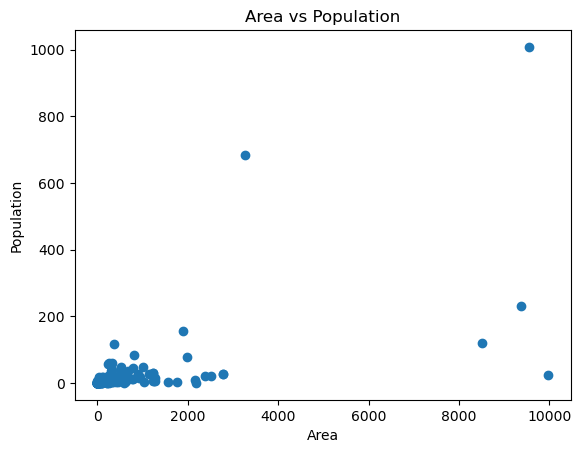

In [20]:
import matplotlib.pyplot as plt

plt.scatter(flags_df['area'], flags_df['population'])
plt.xlabel('Area')
plt.ylabel('Population')
plt.title('Area vs Population')
plt.show()

In [23]:
print(type(flags_df))       # memastikan tipenya DataFrame
print(flags_df.shape)       # jumlah baris dan kolom
print(flags_df.columns)     # nama kolom
display(flags_df.head())    # contoh 5 baris pertama

<class 'pandas.core.frame.DataFrame'>
(175, 26)
Index(['landmass', 'zone', 'area', 'population', 'language', 'religion',
       'bars', 'stripes', 'colours', 'circles', 'crosses', 'saltires',
       'quarters', 'sunstars', 'crescent', 'triangle', 'icon', 'animate',
       'text', 'red', 'green', 'blue', 'yellow', 'white', 'black', 'orange'],
      dtype='object')


,landmass,zone,area,population,language,religion,bars,stripes,colours,circles,...,icon,animate,text,red,green,blue,yellow,white,black,orange
0,5,1,648.0,16.0,10,2,0.0,3.0,5.0,0.0,...,1,0,0,1,1,0,1,1,1,0
1,3,1,29.0,3.0,6,6,0.0,0.0,3.0,0.0,...,0,1,0,1,0,0,1,0,1,0
2,4,1,2388.0,20.0,8,2,2.0,0.0,3.0,0.0,...,0,0,0,1,1,0,0,1,0,0
3,6,3,0.0,0.0,1,1,0.0,0.0,5.0,0.0,...,1,1,0,1,0,1,1,1,0,1
4,4,2,1247.0,7.0,10,5,0.0,2.0,3.0,0.0,...,1,0,0,1,0,0,1,0,1,0


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_graphviz

label_cols = ['red', 'green', 'blue', 'yellow', 'white', 'black', 'orange']

X = flags_df.drop(columns=label_cols)
y = flags_df[label_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=123
)

tree_model = DecisionTreeClassifier(random_state=123)
tree_model.fit(X_train, y_train)

export_graphviz(
    tree_model,
    out_file="flags_tree.dot",
    feature_names=X_train.columns.tolist(),
    rounded=True,
    filled=True
)

In [27]:
label_cols = ['red', 'green', 'blue', 'yellow', 'white', 'black', 'orange']

X = flags_df.drop(columns=label_cols)
y = flags_df[label_cols]

tree_model.fit(X, y)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,123
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


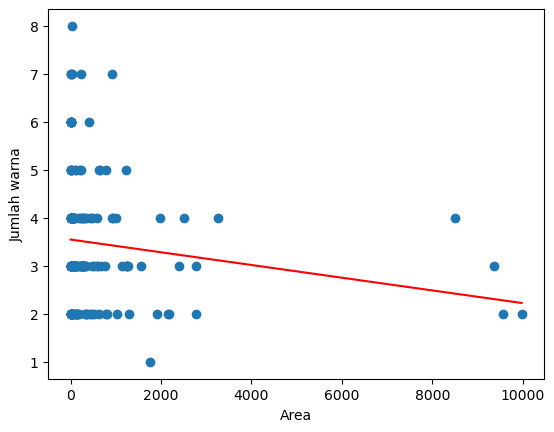

In [30]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

data = flags_df[['area', 'colours']].dropna()
area = data[['area']]       # tetap 2D untuk sklearn
colours = data['colours']

linreg = LinearRegression()
linreg.fit(area, colours)

urutan = area['area'].argsort()
plt.scatter(area['area'], colours)
plt.plot(
    area['area'].iloc[urutan],
    linreg.predict(area.iloc[urutan]),
    color='red'
)
plt.xlabel('Area')
plt.ylabel('Jumlah warna')
plt.show()

In [31]:
area = flags_df[['area']]
colours = flags_df['colours']

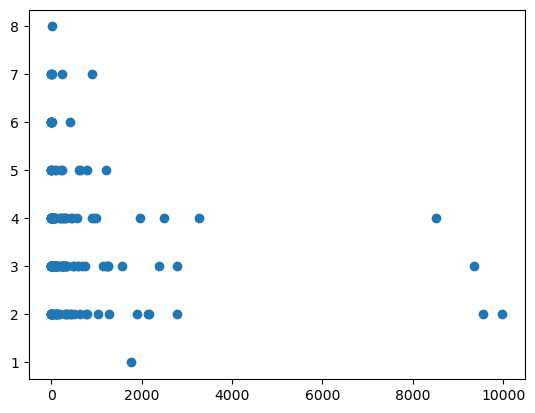

In [33]:
plt.scatter(area, colours)

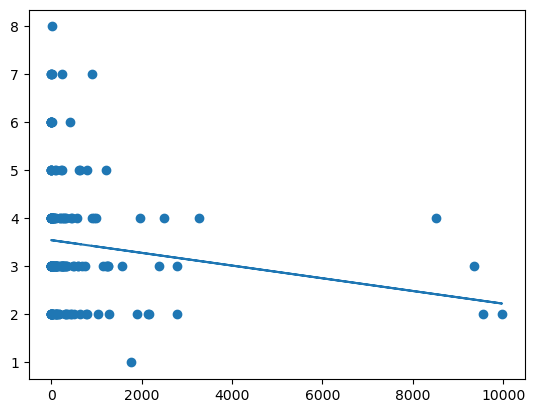

In [34]:
plt.scatter(area, colours)
plt.plot(area, linreg.predict(area))

In [39]:
import pandas as pd
df = pd.read_csv('flags_test_fold_1.csv')

In [40]:
df.head()

,landmass,zone,area,population,language,religion,bars,stripes,colours,circles,...,icon,animate,text,red,green,blue,yellow,white,black,orange
0,3,1,0.0,0.0,6,0,3.0,0.0,3.0,0.0,...,0,0,0,1,0,1,1,0,0,0
1,6,2,7690.0,15.0,1,1,0.0,0.0,3.0,0.0,...,0,0,0,1,0,1,0,1,0,0
2,5,1,143.0,90.0,6,2,0.0,0.0,2.0,1.0,...,0,0,0,1,1,0,0,0,0,0
3,2,3,1099.0,6.0,2,0,0.0,3.0,3.0,0.0,...,0,0,0,1,1,0,1,0,0,0
4,4,2,28.0,4.0,10,5,0.0,0.0,3.0,1.0,...,0,0,0,1,1,0,0,1,0,0


In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 26 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   landmass    19 non-null     int64  
 1   zone        19 non-null     int64  
 2   area        19 non-null     float64
 3   population  19 non-null     float64
 4   language    19 non-null     int64  
 5   religion    19 non-null     int64  
 6   bars        19 non-null     float64
 7   stripes     19 non-null     float64
 8   colours     19 non-null     float64
 9   circles     19 non-null     float64
 10  crosses     19 non-null     float64
 11  saltires    19 non-null     float64
 12  quarters    19 non-null     float64
 13  sunstars    19 non-null     float64
 14  crescent    19 non-null     int64  
 15  triangle    19 non-null     int64  
 16  icon        19 non-null     int64  
 17  animate     19 non-null     int64  
 18  text        19 non-null     int64  
 19  red         19 non-null     int

In [43]:
data = df.drop(columns=['area'])
data = pd.get_dummies(data)
data

,landmass,zone,population,language,religion,bars,stripes,colours,circles,crosses,...,icon,animate,text,red,green,blue,yellow,white,black,orange
0,3,1,0.0,6,0,3.0,0.0,3.0,0.0,0.0,...,0,0,0,1,0,1,1,0,0,0
1,6,2,15.0,1,1,0.0,0.0,3.0,0.0,1.0,...,0,0,0,1,0,1,0,1,0,0
2,5,1,90.0,6,2,0.0,0.0,2.0,1.0,0.0,...,0,0,0,1,1,0,0,0,0,0
3,2,3,6.0,2,0,0.0,3.0,3.0,0.0,0.0,...,0,0,0,1,1,0,1,0,0,0
4,4,2,4.0,10,5,0.0,0.0,3.0,1.0,0.0,...,0,0,0,1,1,0,0,1,0,0
5,4,1,4.0,3,5,3.0,0.0,3.0,0.0,0.0,...,0,0,0,1,0,1,1,0,0,0
6,3,1,54.0,3,0,3.0,0.0,3.0,0.0,0.0,...,0,0,0,1,0,1,0,1,0,0
7,5,1,39.0,6,2,0.0,3.0,3.0,0.0,0.0,...,1,0,1,1,1,0,0,1,0,0
8,1,4,2.0,1,1,0.0,0.0,3.0,0.0,0.0,...,0,0,0,0,1,0,1,0,1,0
9,4,2,6.0,10,5,0.0,3.0,3.0,0.0,0.0,...,0,0,0,1,1,0,0,0,1,0


In [44]:
label_cols = ['red', 'green', 'blue', 'yellow', 'white', 'black', 'orange']

X = flags_df.drop(columns=label_cols)  # atribut bendera
y = flags_df[label_cols]              # label warna

In [50]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X)
scaled_data = scaler.transform(X)
scaled_data = pd.DataFrame(scaled_data, columns= X.columns)
scaled_data.head()

,landmass,zone,area,population,language,religion,bars,stripes,colours,circles,crosses,saltires,quarters,sunstars,crescent,triangle,icon,animate,text
0,0.949801,-0.938834,0.057139,-0.067263,1.374633,-0.070457,-0.420096,0.605386,1.165994,-0.363803,-0.394003,-0.294884,-0.345813,-0.083093,-0.258985,-0.408248,1.725478,-0.517799,-0.306186
1,-0.338689,-0.938834,-0.362610,-0.205121,0.220864,1.902352,-0.420096,-0.671031,-0.362463,-0.363803,-0.394003,-0.294884,-0.345813,-0.083093,-0.258985,-0.408248,-0.579550,1.931251,-0.306186
2,0.305556,-0.938834,1.237048,-0.024845,0.797748,-0.070457,1.594061,-0.671031,-0.362463,-0.363803,-0.394003,-0.294884,-0.345813,-0.083093,3.861229,-0.408248,-0.579550,-0.517799,-0.306186
3,1.594046,0.561586,-0.382275,-0.236934,-1.221346,-0.563660,-0.420096,-0.671031,1.165994,-0.363803,-0.394003,-0.294884,-0.345813,-0.303416,-0.258985,2.449490,1.725478,1.931251,-0.306186
4,0.305556,-0.188624,0.463326,-0.162703,1.374633,1.409150,-0.420096,0.179914,-0.362463,-0.363803,-0.394003,-0.294884,-0.345813,-0.083093,-0.258985,-0.408248,1.725478,-0.517799,-0.306186


In [51]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(scaled_data, y, test_size=0.2, random_state=1)

In [56]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

model = OneVsRestClassifier(LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

,estimator,LogisticRegre...max_iter=1000)
,n_jobs,None
,verbose,0
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None


In [57]:
model.score(X_test, y_test)

0.2571428571428571